# Discrete Morse Compression

This notebook will demonstrate the clean usage of this supplementary repository for the `Mimic-mjx` package, particularly for the `mimic_mjx.analysis` module, which allows user to load the checkpoint from the previous training run, and perform a rollout of the checkpoint with minimal dependencies on the system (other than the cluster environment). This module abstracted away all the boilerplate codes for initializing the environment, and it is very clean and digestible, while customizable for any type of data analysis that wants tobe performed on teh data generated by `Mimic-mjx`.

In [1]:
import os
os.chdir('..')

# Step 1: Imports

In [2]:
rodent_rollout_dir = "/root/vast/kaiwen/TopoVNL/data/rodent_ar"
num_clips = 500

In [46]:
%env MUJOCO_GL=egl
%env PYOPENGL_PLATFORM=egl
%matplotlib inline
%load_ext autoreload
%autoreload 2

import numpy as np
import multiprocessing as mp
import functools
import os
import pickle as pkl
import matplotlib.pyplot as plt
import seaborn as sns
import umap
import networkx as nx
import h5py

from tqdm import tqdm
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from vnl_tda.utils.load_utils import (
    get_aggregate_data,
)

from vnl_tda.pipelines.tda.skeletonization.preprocess import (
    estimate_delay_embedding_params
)

from vnl_tda.pipelines.tda.skeletonization.postprocess import (
    cluster_vpath_with_wasserstein2d_fixedlen_kmeans,
    chunk_loops_by_clustered_vpath,
    build_cluster_prototypes_from_dict,
    cluster_distance_matrix,
    cluster_knn_graph,
)

from vnl_tda.pipelines.tda.skeletonization.plotting import (
    plot_vpath_cluster,
    plot_dimo,
    plot_dimo_longest_cycle,
    plot_desc_flow,
    plot_eigenbase_compression_loss,
    plot_eigenbase_cross_reconstruction,
    plot_cluster_eigenbase_cross_reconstruction,
    plot_cluster_principal_angles_to_target_union,
    plot_cluster_subspace_mds,
    plot_cluster_eigenbase_reconstruction_box,
    compare_clusters_axis_motion_with_union,
    )

from vnl_tda.pipelines.tda.skeletonization.rendering import (
    render_clip_grid,
    render_crossclip_paths_to_minima,
    render_original_plus_top2_cycles,
    render_crossclip_cycles_side_by_side,
    render_grid_clusters_side_by_side,
)

env: MUJOCO_GL=egl
env: PYOPENGL_PLATFORM=egl
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Check the keys of teh folder to ensure we have everything using the below:

In [4]:
with h5py.File(rodent_rollout_dir + "/clip_0.h5", "r") as f:
    print(list(f.keys()))

['ctrl', 'intention', 'obs', 'qpos', 'reward']


---

# Step 2: Loading, Background, & Labeling

Reload intention to use the latest AR intention first:

In [5]:
work_rodent = functools.partial(get_aggregate_data, "/intention", [], path=rodent_rollout_dir)

with mp.Pool(processes=mp.cpu_count()) as pool:
    int_rodent = list(tqdm(pool.imap(work_rodent, range(num_clips)), total=num_clips))

int_rodent = np.vstack(int_rodent)

100%|██████████| 500/500 [00:00<00:00, 4801.08it/s]


Firstm let's create a 3D background embedding from different dimensionality reduction projections (PCA, TSNE, UMAP) for visualization of the cycles that got identified

In [6]:
from vnl_tda.pipelines.gaitcycle.utils import (
    create_time_windows
)

int_rodent = int_rodent.reshape([num_clips, 499, 16])

window_size = 20
stride = 10
pts_per_clip = []
centers_per_clip = []
for clip in int_rodent:
    windows, centers = create_time_windows(
        clip,
        windows_size=window_size,
        stride=stride
    )
    pts_per_clip.append(windows)
    centers_per_clip.append(centers)

all_windows = np.vstack(pts_per_clip)
print(np.array(pts_per_clip).shape, all_windows.shape)

embeds3d = []
emb_pca3d = PCA(n_components=3, random_state=42).fit_transform(all_windows)
embeds3d.append((emb_pca3d, "PCA 3D"))

emb_tsne3d = TSNE(n_components=3, perplexity=30, init="pca", random_state=42).fit_transform(all_windows)
embeds3d.append((emb_tsne3d, "t-SNE 3D"))

emb_umap3d = umap.UMAP(n_components=3, n_neighbors=15, random_state=42).fit_transform(all_windows)
embeds3d.append((emb_umap3d, "UMAP 3D"))

(500, 48, 320) (24000, 320)


/root/miniforge3/envs/track-mjx/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## Manual Labels
We manually labeled each clip with multi-behaviors, including one or more of the following:

- `rear`: any rearing behavior, the torso $z$ must be lifted for rearing to count.
- `walk`: any form of gait that causes changes in $(x,y)$ location of the agent.
- `walk_wait`: any pause of gait movement during an changing $(x,y)$ location process, `walk_wait` and `walk` can simulatneuously occur.
- `head_turn_z`: any head lift movement that is not a rear (i.e. no torso movement), obnly head movement is allowed, usually during groom to look up.
- `head_turn_xy` any visiable head turning on the $(x,y)$ plain,w hich may result in an change in the direction of movement, can occur during `walk` or `groom_up/down` or `rear` (small shaking of head doesn't count).
- `groom_down`: any grooming where the animal is looking downward or into it's torso.
- `groom_up`: any grooming that is sustaining it's head, differences with `head_turn_z` is the duration of the behavior, usually companion with limb movement.

During clustering, each discrete motifs are the following:
- `walk` = `walk` and `walk_wait` presented only.
- `rear` = `head_turn_z` and `rear` presented only.
- `groom` = `groom_up` and `groom_down` presented only.
- `turn` = `head_turn_xy`, which do not need to be the only motif presented, as long as it is presented, it counts.
- `wait` = `walk_wait`, which do not need to be the only motif presented, as long as it is presented, it counts.

**Then combinations are made by taking the union of these discrete sets, not intersections**, which may introduce irrelevant nosies in teh clips, but will maximally include all the presented behaviors.

Use the following to produce a grid view to better visualize each clip:

In [12]:
clip_ids = np.arange(100,200)
out = render_clip_grid(
    rodent_rollout_dir,
    clip_ids=clip_ids,
    rows=10,
    cols=10,
    out_path="dm_videos/all_behaviors_100_200.mp4",
    camera_name="close_profile",
    fps=40,
    target_size=(320, 240),
    title="Raw Clips Grid",
    per_tile_labels=True
)
print("Wrote:", out)

# Step 3: Discrete Morse Graph Compression

## Step 3.1: Discrete Morse graph per clip

We will need to do a couple of checks to ensure that the PCD package is compiled correctly:

In [7]:
repo_path = "/root/vast/kaiwen/TopoVNL/PCD-Graph-Recon-DM"
os.chdir(repo_path)
print("Changed working directory to:", os.getcwd())

import dmpcd.pcd as pcd
import inspect
import subprocess
import tempfile

print("Source file location:")
print(inspect.getfile(pcd))

# check the compute_persistence_swr function to see if it calls the executable
print("\nFunction source (first 50 lines):")
source = inspect.getsource(pcd.compute_persistence_swr)
print(source[:2000])

Changed working directory to: /root/vast/kaiwen/TopoVNL/PCD-Graph-Recon-DM
Source file location:
/root/vast/kaiwen/TopoVNL/PCD-Graph-Recon-DM/dmpcd/pcd/__init__.py

Function source (first 50 lines):
def compute_persistence_swr(input_filename, output_dir):
    if not os.path.exists(output_dir):
        os.mkdir(output_dir)
    command = "./dmpcd/code/persistence_swr/spt_cpp " + input_filename + ' ' + output_dir + ' 0 1'
    os.system(command)



In [8]:
repo_path = "/root/vast/kaiwen/TopoVNL/PCD-Graph-Recon-DM"

exe_paths = [
    "dmpcd/code/persistence_swr/spt_cpp",
    "dmpcd/code/phat_morse_src/a.out"
]

print("Checking executables:")
for exe in exe_paths:
    full_path = os.path.join(repo_path, exe)
    exists = os.path.exists(full_path)
    executable = os.access(full_path, os.X_OK) if exists else False
    
    if exists and executable:
        print(f"✓ {exe}")
        try:
            result = subprocess.run([full_path], capture_output=True, timeout=2)
            print(f"  Can execute: YES")
        except Exception as e:
            print(f"  Can execute: NO - {e}")
    else:
        print(f"✗ {exe} - {'EXISTS but NOT EXECUTABLE' if exists else 'NOT FOUND'}")

Checking executables:
✓ dmpcd/code/persistence_swr/spt_cpp
  Can execute: YES
✓ dmpcd/code/phat_morse_src/a.out
  Can execute: YES


## Tunning $m$ and $\tau$ systematically:
We can do this much more robustly with mutual information minimum (for $\tau$) and false knn (for $k$):

AMI per clip: 100%|██████████| 100/100 [00:03<00:00, 32.12it/s]


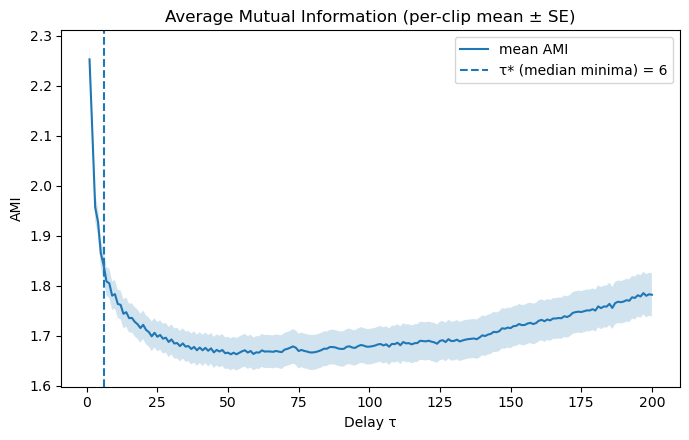

FNN per clip (τ=6): 100%|██████████| 100/100 [00:16<00:00,  5.99it/s]


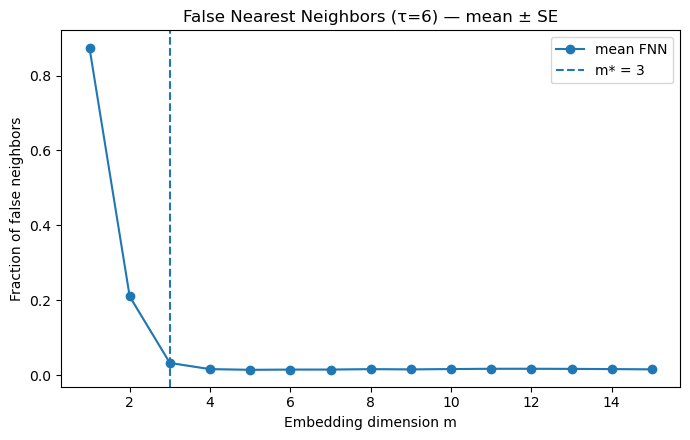

Selected τ* (median per-clip minima): 6
Selected m*: 3


In [19]:
work_rodent = functools.partial(get_aggregate_data, "/intention", [], path=rodent_rollout_dir)

tau_star, m_star, diag = estimate_delay_embedding_params(
    rodent_rollout_dir=rodent_rollout_dir,
    get_aggregate_data_fn=get_aggregate_data,
    num_clips=500,
    clip_indices=range(500),
    plot=True
)
print("τ* =", tau_star, "m* =", m_star)

## Fitting with only varying $k$ and $\delta$ ($m$ and $\tau$ fixed):
When fixing the number of dimension $m$ and the delay $\tau$, we can try to hypertune teh number of neighbors $k$ and the $\delta$.

Loading: tuning_results_20251022_035351.pkl


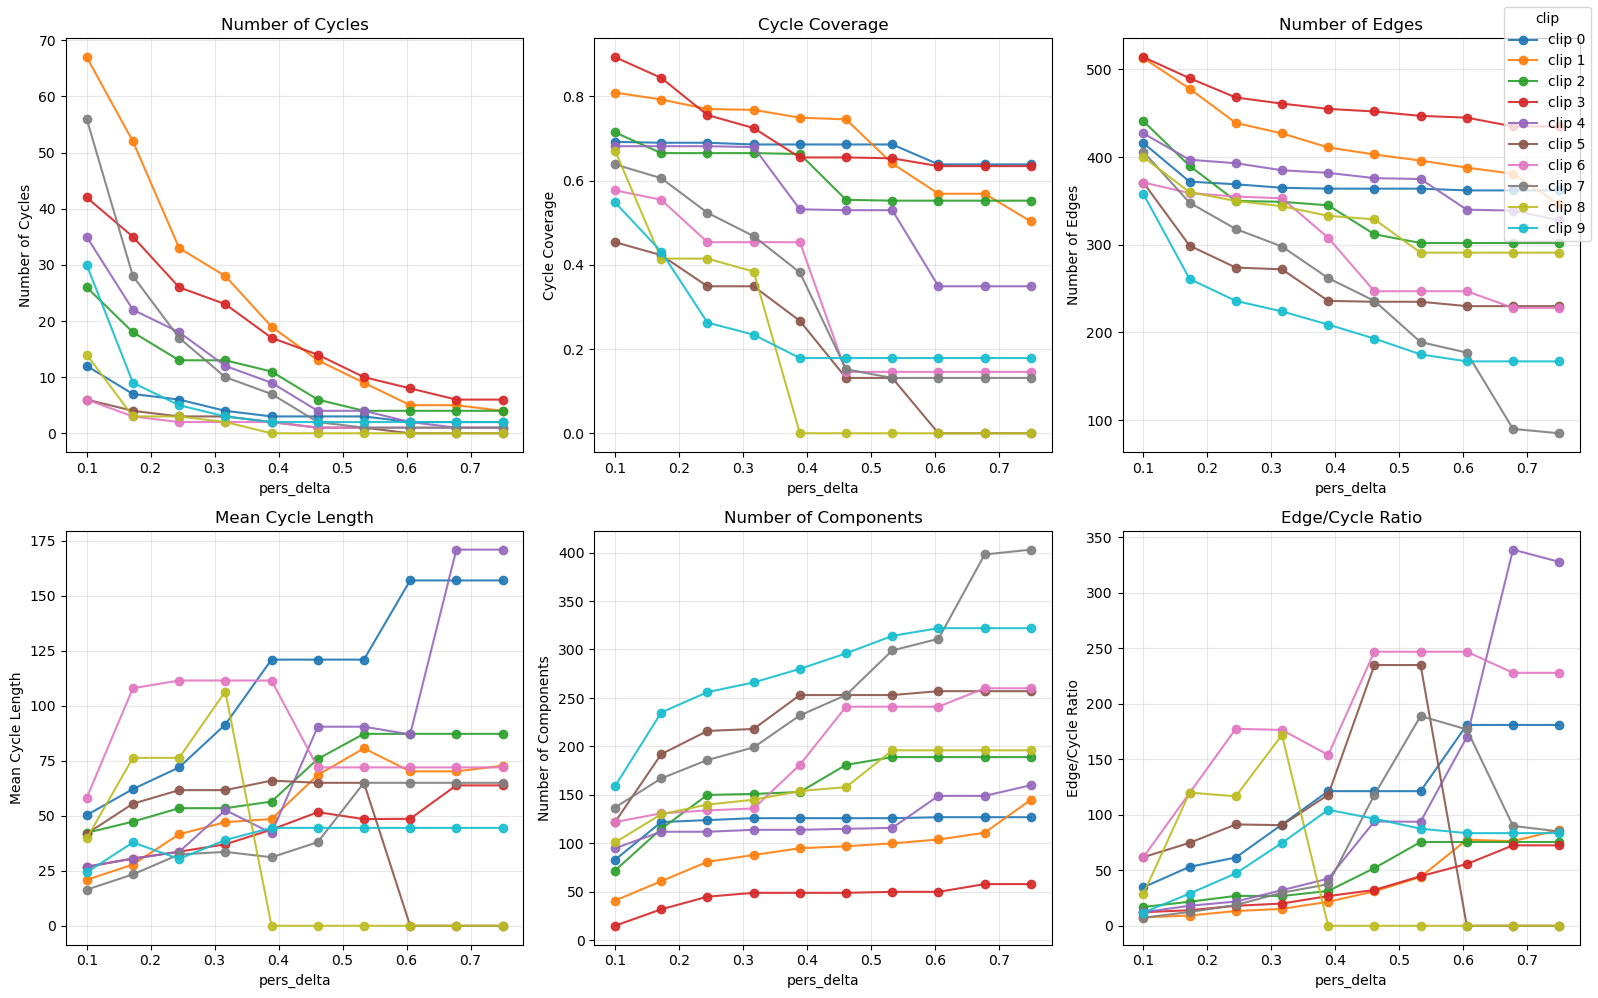

In [27]:
base_dir = "dm_tuning_takens_m3_tau6_10clips"
files = [f for f in os.listdir(base_dir) if f.startswith("tuning_results_") and f.endswith(".pkl")]
latest_file = sorted(files)[-1]
print("Loading:", latest_file)

with open(os.path.join(base_dir, latest_file), "rb") as f:
    data = pkl.load(f)
results_df = data["results_df"]

def plot_tuning_by_clip(results_df, metrics=None):
    df = results_df[results_df["success"] == True].copy()
    if metrics is None:
        metrics = [
            ("num_cycles", "Number of Cycles"),
            ("cycle_coverage", "Cycle Coverage"),
            ("num_edges", "Number of Edges"),
            ("mean_cycle_length", "Mean Cycle Length"),
            ("num_components", "Number of Components"),
            ("edge_cycle_ratio", "Edge/Cycle Ratio"),
        ]

    unique_clips = sorted(df["clip_id"].unique())
    unique_k = sorted(df["k_neighbors"].unique())
    palette = sns.color_palette("tab10", len(unique_clips))
    color_map = {cid: palette[i % len(palette)] for i, cid in enumerate(unique_clips)}

    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    for ax, (metric, title) in zip(axes.flat, metrics):
        labeled = set()
        for cid in unique_clips:
            for k in unique_k:
                subset = df[(df["clip_id"] == cid) & (df["k_neighbors"] == k)].sort_values("pers_delta")
                if subset.empty:
                    continue
                x = subset["pers_delta"].values
                y = subset[metric].values
                lbl = f"clip {cid}" if cid not in labeled else None
                ax.plot(x, y, "o-", color=color_map[cid], alpha=0.9, label=lbl)
                if lbl is not None:
                    labeled.add(cid)
        ax.set_xlabel("pers_delta")
        ax.set_ylabel(title)
        ax.set_title(title)
        ax.grid(True, alpha=0.3)

    handles, labels = axes.flat[-1].get_legend_handles_labels()
    fig.legend(handles, labels, title="clip", loc="upper right")
    plt.tight_layout()
    plt.show()

plot_tuning_by_clip(results_df)

## Establishing DM graph upon each clip level

- The higher the persistence, the less the cycles (positive edges) that we will be keeping, but this does not directly effect the stable manifold of negative edges.
- Would this persistence threshold be dealing with the **grandularity** of the features found?
- This is a single run of the discrete moarse graph reconstruction algorithm in PCD repository, one clip would take about 10 seconds to process.

In [9]:
base_output_dir = "/root/vast/kaiwen/TopoVNL/PCD-Graph-Recon-DM/dm_results_m3_tau6_p0.75"
with open(os.path.join(base_output_dir, "all_G_sm.pkl"), "rb") as f:
    all_G_sm = pkl.load(f)
with open(os.path.join(base_output_dir, "all_cycle_dm.pkl"), "rb") as f:
    all_cycle_dm = pkl.load(f)

print(f"Loaded {len(all_G_sm)} graphs and {len(all_cycle_dm)} loop sets")

Loaded 800 graphs and 800 loop sets


The discrete-Morse skeleton (`dimo_edge.txt`) built from the surviving critical edges is not necessarily acyclic. By definition, if the original data had persistent cycles (H₁ features), they must still exist somewhere in the skeleton.

Loading in results processed instead of using the ones trained in notebook. The dm graph computation will results in a few things:
1. `dimp_edge.txt` is the final edges that persist after the persistence threshold (true edges in the stable manifold) --> only record descending or ascending by +1 or -1
2. `edge_for_morse_only.txt` is the set of edges (i, j) used by the Discrete Morse (DM) reconstruction algorithm, which records the filtration value in the last column
3. `edge.txt` is the k-nearest-neighbor–style; it encodes the base geometry used for the subsequent discrete Morse computation.

Counts -> -1: 290, +1: 8, 2: 2


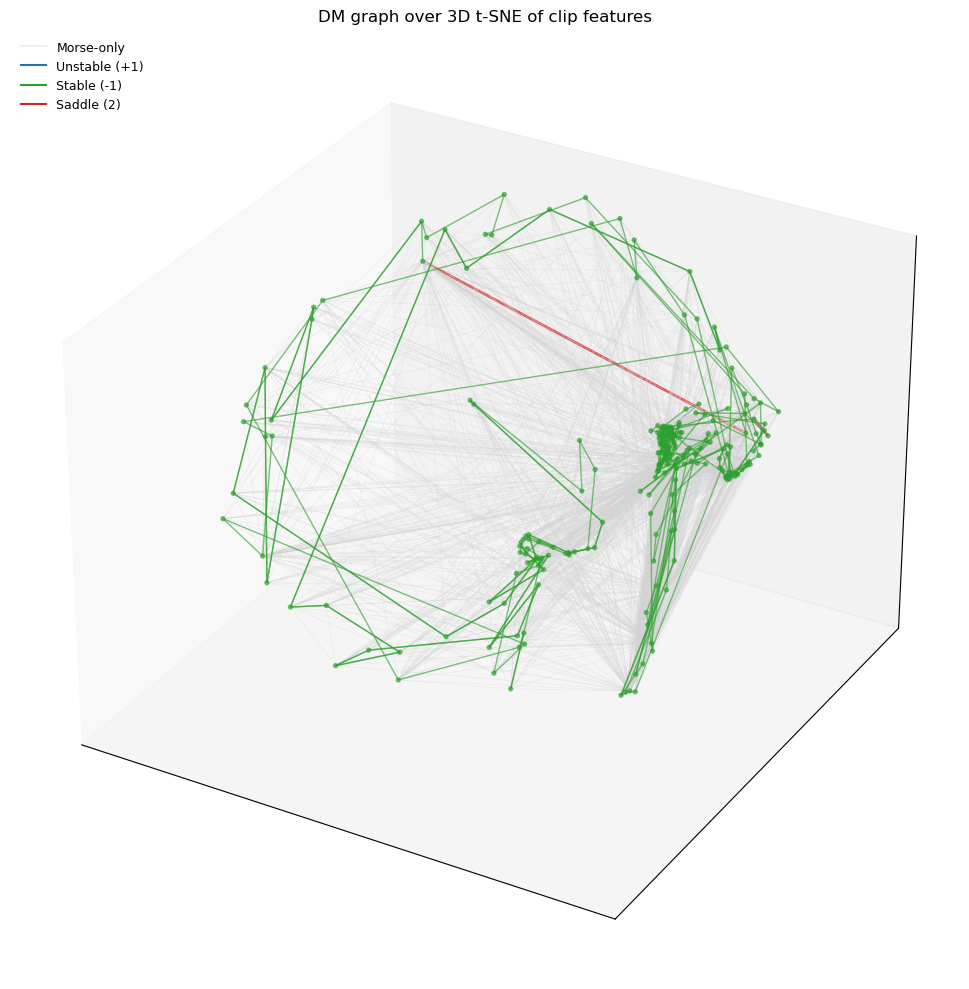

In [38]:
clip_dir = os.path.join(base_output_dir, "clip_23")
edge_path = os.path.join(clip_dir, "0.75/dimo_edge.txt")
G, pos, coords3d = plot_dimo(edge_path, clip_dir, tsne_kwargs=None)

`networkx.minimum_cycle_basis` will internalluy builds a spanning tree of the graph and for each non-tree edge (a “back edge” that closes a loop), it computes the fundamental cycle created by adding that edge to the tree. At last, it finds the smallest independent subset of these cycles that spans the cycle space, minimizing total length.

The above results should be equivalent of building MST upon this reconstructed skeleton --> and then finds the edge not on the MST and the shortest path it will take to reach the root from this path --> this is similar to what we do during graph construction, just that now we are performing on the simplified skeleton.

In [50]:
clip_dir = os.path.join(base_output_dir, "clip_23")
edge_path = os.path.join(clip_dir, "0.75/dimo_edge.txt")
cycles, UG, pos3d, coords3d = plot_dimo_longest_cycle(edge_path, clip_dir, tsne_kwargs=None, top_k=1)

## Central Spine

***Observation***: seems like the dm-graph is not doing what we were hoping, it is incapable of distilling out the different attractors of behavior. It is more or less just finding the one generative cycle that generates all of the rest of the data, but not neccessarily having it in the form of $k$ loops for $k$ behavior.

- The number of cycles that we can find really depends on how many loops are enclosed during the filtration time. We are seeing nested level-set components merging at different filtration values: one 1-cycle (short-lived one) is born and dies inside the lifespan of the larger, more persistent 1-cycle.


***Revisit Theory***: Skeletonization is a geometric condensation of the intention trajectory manifold (down-sampling it into topological loops and junctions), not a dynamical decomposition into attractors, so the results that we observed makes sense. From a combinatorial perspective, each of the `2` edges would be the edge that closes a loop in the original data space, so they are the true positive edges; it's unpaired as it does not participate in the local gradient flow. Alternatively, in the 1-simplex's density filed perspective, this is the saddle point, the junction of high-density region.

- It's really about the 1-simplex (edges) here instead of the 0-simplex (nodes), 

- The order of the cycle is defined by the critical non-tree edge $(u,v)$ amd the unique simple path (since MST) $P(u,v)$ found in tree $T$, which supposeively serves as the stable manifold backbone.

- For a cycle to exist, the boundary operator of it would be 0 $\partial C = 0$, meaning that it's a non-trivial element of homology and cannot be contracted away without tearing the structure of the original manifold. The discrete gradient descent/ascent paths cannot collapse it to a tree. Therefore, this serve as a **[central hub?]** where any traversal of reasonable intention must cross such place.

- The the underlaying manifold (at least from the topology’s perspective) may not particular behavior attractor, but rather transitions between behaviors (i.e. stereotypical behavior sequence).

Ideally, we would want to put clips with similar behaviors (i.e. all walk-rear combo) together and perform this operation upon. This would chain a sequence of **[basis?]** behavior that any reasonable sequence of the targeted behavior (i.e. walk-rear) must come across this spine at some point.

- When performing this operation on a diverse set of behavior, we should observe either one big loop describing relationship and transition between all there behavior, or smaller loop describing combination of either and then the other independent loop standing out.

/tmp/ipykernel_10106/2746304266.py:44: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab10", max(1,len(mins)))


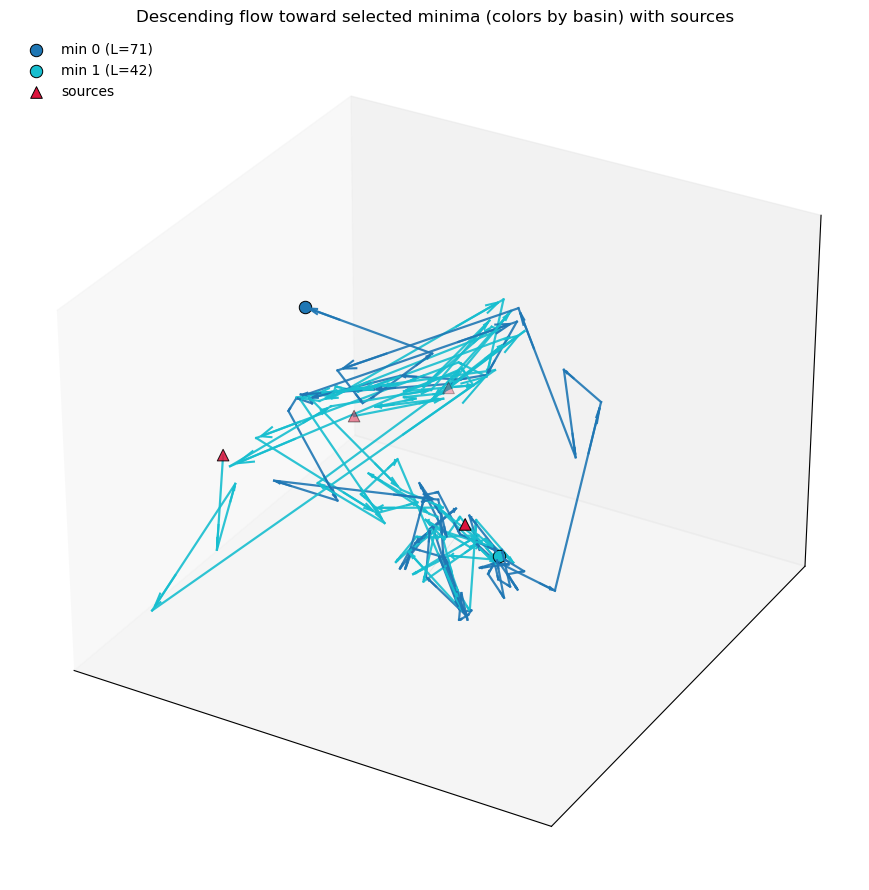

In [30]:
plot_desc_flow(edge_path, coords3d, show_cycle_edges=True, top_k=2)

We can render all teh clip snapshot along with corresponding paths to the minima, video will be saved to external folder:

In [12]:
clip_idx = 100
out = render_original_plus_top2_cycles(rodent_rollout_dir,
                                       clip_id=clip_idx,
                                       cycles=cycles,
                                       out_path=f"dm_videos/cycles_clip_{clip_idx}_top1.mp4",
                                       fps=40,
                                       target_size=(320,240),
                                       title="Original | Top-1 Cycles",
                                       col_labels=True
                                       )

MuJoCo Rendering...


100%|██████████| 500/500 [00:01<00:00, 304.33it/s]
[libx264 @ 0x411cca00] -qscale is ignored, -crf is recommended.


## Step 3.2: Discrete Moarse graph for different behavior intention pools

Establishing DM graph upon the whole intention pool, this will help us discover some of the stated goals in our hypothesis, but this will take very long to run, so we need to run it with `screen mode`:

In [31]:
base_output_dir = "/root/vast/kaiwen/TopoVNL/PCD-Graph-Recon-DM/dm_results_pool_m3_tau6_p0.75_any_walk_rear"
with open(os.path.join(base_output_dir, "all_G_dm.pkl"), "rb") as f:
    all_G_sm = pkl.load(f)
with open(os.path.join(base_output_dir, "all_cycle_dm.pkl"), "rb") as f:
    all_cycle_dm = pkl.load(f)

print(f"Loaded {len(all_G_sm)} graphs and {len(all_cycle_dm)} loop sets")

Loaded 3409 graphs and 8 loop sets


In [24]:
clip_ids = [0, 2, 5, 9, 13, 20, 21]
out = render_crossclip_cycles_side_by_side(
    rodent_rollout_dir=rodent_rollout_dir,
    clip_ids=clip_ids,
    cycles=cycles,
    out_path="dm_videos/crossclip_cycles.mp4",
    camera_name="close_profile",
    fps=5,
    target_size=(320, 240),
    title="Cycles (cross-clip)",
    per_tile_labels=True,
    cycle_labels=["Cycle A", "Cycle B"]
)
print("Wrote:", out)

There exist multiple minimum (where no gradient edge exist) and there exist multiple source where this gradient path can exist. This is showing the persistent flow to the denseist intenton (have most neighbor) in the data.

Observations:
- Dense regions are alike yet showing different behaviors (rear is one, walk is the other).
- Different "areas" of the descending path shows universalness in some behavior: no matter where you start, some pathway is neccessary.
- We can see how different initial starting point of behaviors can be chained  and connected to different pathways that lead to the same ending.

In [56]:
render_crossclip_paths_to_minima(
    rodent_rollout_dir=rodent_rollout_dir,
    clip_ids= [0, 2, 5, 9, 13, 20, 21],
    edge_path=edge_path,
    out_path="dm_videos/stable_manifold_path.mp4",
    camera_name="close_profile",
    fps=10,
    target_size=(320,240),
    title="Descending pathways to minima (cross-clip)",
    per_tile_labels=True,
    num_paths=3
)

---

# Step 4: Compression Based Clustering

Each clip's cycle is a **distinct geneartive feature** of the clip (it's the distinct feature, maybe recurrent movement, that would most likely happen movement in the clip because it is there so many times) that signifies the rest of the movement, by comparing these cycles with each other, we should be able to cluster them based on the Wasserstein distance between these identified intentions.

In addition, we have to remanber that intention is about the motor commands, it's the abstract signal of control, so stationary rear and standing still may belong to the same cluster, think from an actuation's perspective.

In [10]:
cluster_dict, all_cleaned_loops, D, Dn, windows, labels = cluster_vpath_with_wasserstein2d_fixedlen_kmeans(all_cycle_dm, int_rodent, pad=0,
                                                  min_len=0, max_len=500, n_clusters=10, n_clips=500,
                                                  drop_nearby_loop_num=0, skip_clips=[37, 152, 163, 274, 281], 
                                                  squared_cost=False, only_max=False, use_full_union=False, return_mats=True)

/root/miniforge3/envs/track-mjx/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


We can plot each clusters with overlay on the dimensionality projection that we did earlier:
- Note that we are clustering each path (numerous frames), we need tobreak them up:

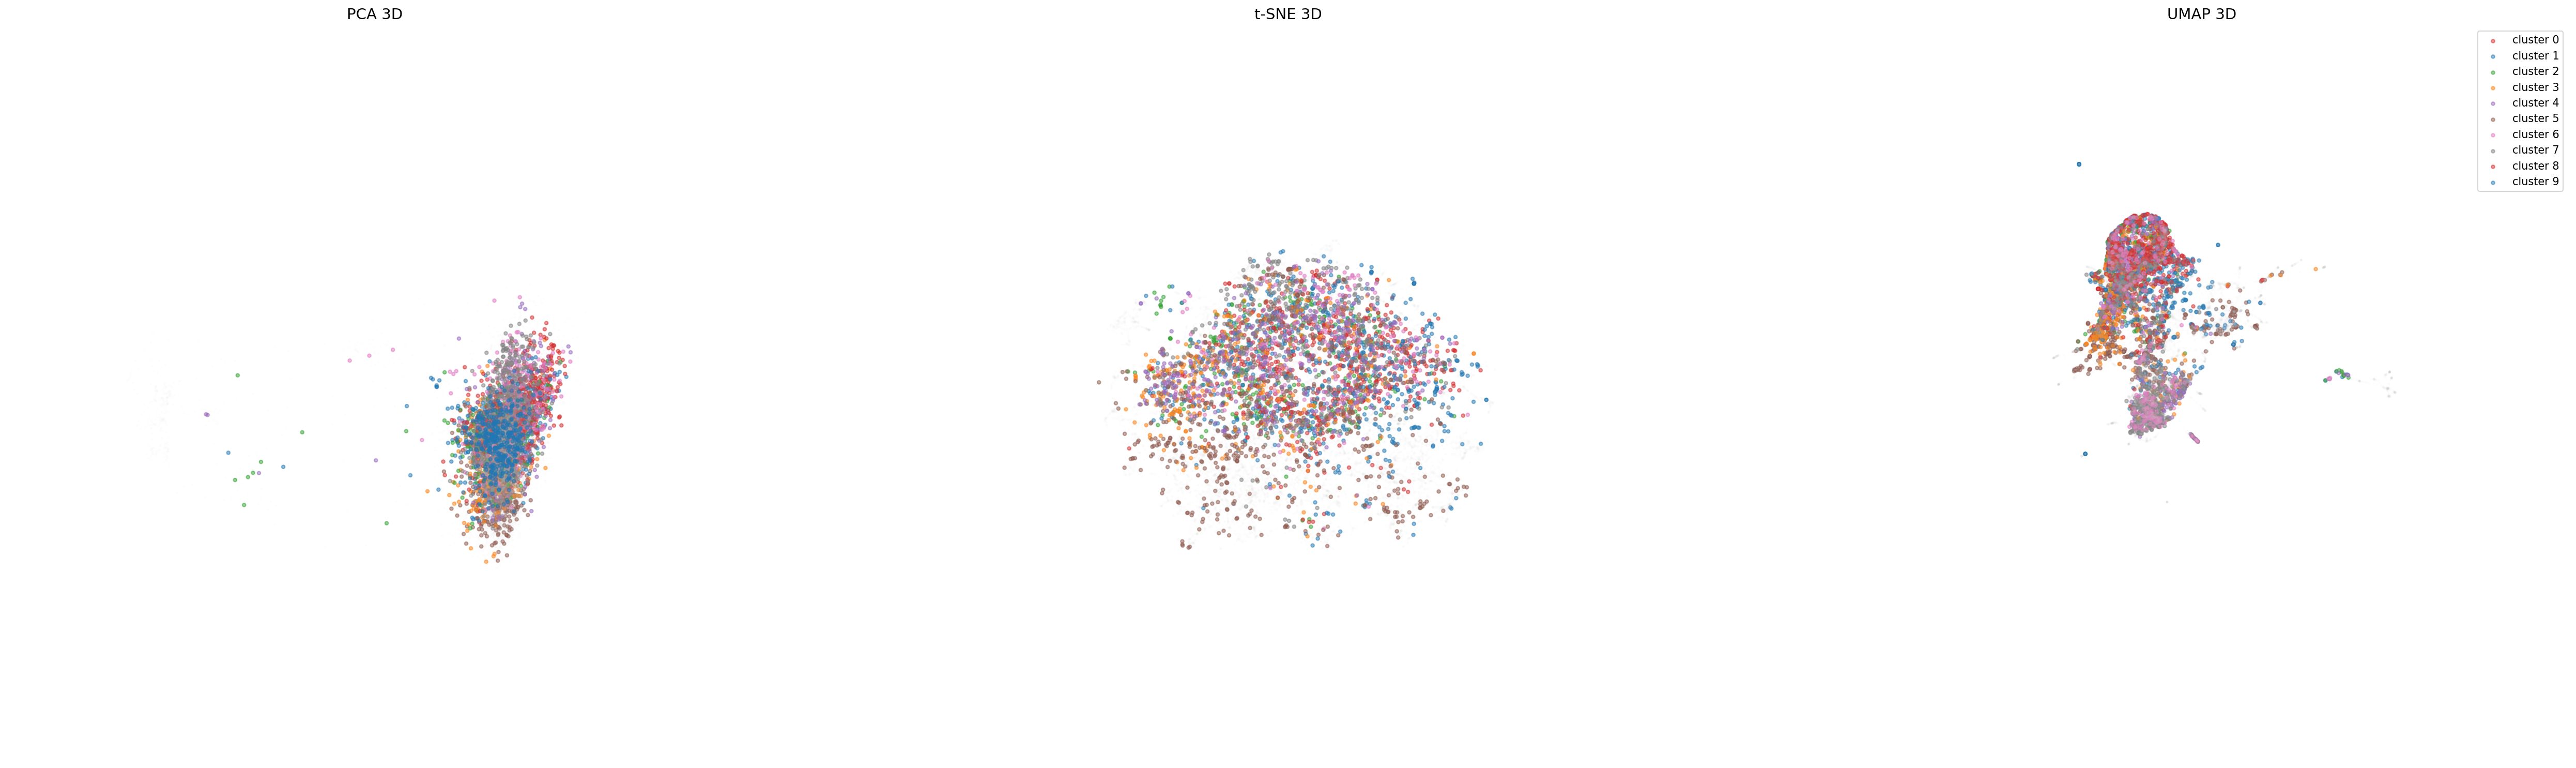

Saved combined plot to vpath_cluster_all.png


In [17]:
clip_frame_to_global = {}
offset = 0
for cid, centers in enumerate(centers_per_clip):
    clip_frame_to_global[cid] = {int(frame): offset + i for i, frame in enumerate(centers)}
    offset += len(centers)
    
plot_vpath_cluster(cluster_dict, embeds3d, clip_frame_to_global)

We can now use these clusters to chunk in teh original joint (qpos) state to seperate the frames

In [55]:
cluster_chunks = chunk_loops_by_clustered_vpath(cluster_dict, rodent_rollout_dir, pad=0, sample=5)

In [22]:
render_grid_clusters_side_by_side(
    cluster_chunks=cluster_chunks,
    out_path="dm_videos/selected_clusters_grid_3.mp4",
    framerate=30,
    max_samples_per_cluster=5,
    target_size=(320, 240),
    title="Selected Cluster Samples",
    per_tile_labels=True,
    selected_clusters=np.arange(6,9),
    cluster_labels={
        0: "walk",
        1: "groom_walk",
        2: "walk_turn",
        3: "groom_turn",
        4: "rear_turn_walk",
        5: "groom",
        6: "rear_walk",
        7: "rear",
        8: "walk_turn_stay",
    }
)

[libx264 @ 0x219c4a00] -qscale is ignored, -crf is recommended.


builds the KNN now based on W2 Earth Mover’s Distance (EMD) matrix, we are looking at how distinct sets of behaviors tends to connect to each others:
- The  `target_len`  depends the number of nodes that we can look at, which deternmines how long we want to look at the relationship for.

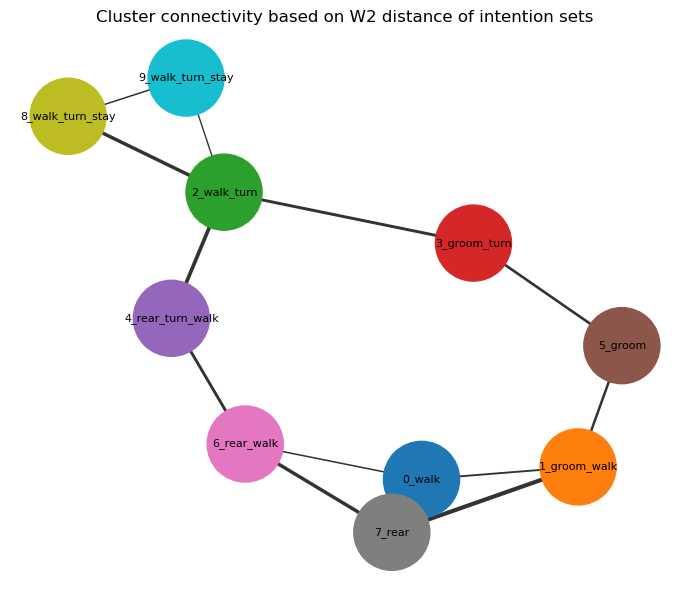

In [14]:
# cluster_labels = {
#     0: "groom_fast_walk",
#     1: "groom_reach_walk",
#     2: "groom_walk",
#     3: "groom_turn",
#     4: "rear_turn_walk",
#     5: "groom_fast_fast_walk",
#     6: "rear_walk",
#     7: "rear",
#     8: "fast_walk_stay",
#     9: "fast_wak_circle",
#     10: "groom",
#     11: "mid_rear",
#     12: "walk_stay",
#     13: "groom_turn",
#     14: "rear_walk"
# }

cluster_labels = {
    0: "walk",
    1: "groom_walk",
    2: "walk_turn",
    3: "groom_turn",
    4: "rear_turn_walk",
    5: "groom",
    6: "rear_walk",
    7: "rear",
    8: "walk_turn_stay",
    9: "walk_turn_stay",
}

def draw_cluster_intention_graph(G, cluster_labels, figsize=(7,6)):
    plt.figure(figsize=figsize)
    pos = nx.spring_layout(G, seed=0)
    node_colors = plt.cm.tab10(np.linspace(0, 1, len(G.nodes())))
    nx.draw_networkx_nodes(G, pos, node_size=3000, node_color=node_colors)
    weights = np.array([d.get("weight", 1) for _, _, d in G.edges(data=True)])
    w_norm = (weights - weights.min()) / (weights.max() - weights.min() + 1e-8)
    nx.draw_networkx_edges(G, pos, width=1 + 2 * w_norm, alpha=0.8, arrows=False)

    labels = {cid: f"{cid}_{cluster_labels[cid]}" for cid in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=8)
    plt.axis("off")
    plt.title("Cluster connectivity based on W2 distance of intention sets")
    plt.tight_layout()
    plt.savefig(
        "cluster_graph.pdf",
        bbox_inches="tight",
        pad_inches=0,
        dpi=300,
        transparent=True,
        format="pdf",
    )
    plt.show()

prototypes = build_cluster_prototypes_from_dict(cluster_dict, int_rodent, target_len=50, agg="mean")
C, ids = cluster_distance_matrix(prototypes, metric="emd")
G = cluster_knn_graph(C, ids, cluster_labels, k=2, threshold=None)
draw_cluster_intention_graph(G, cluster_labels)

---

# Step 6: Compression Loss

We can compute the compression ability for each (1) clip level, (2) pool level, and (3) cluster level cycles. We will compute three things:
- **L2 Eigenvalues Distance**: tell us how variance is distributed across different movement.
    - Self explained: How well does the full spectrum expresses how variance in the full dataset is distributed and how well does the cycle spectrum expresses how variance in cycle frames is distributed.
    - Cross explained: How well does the full spectrum expresses how variance in the cycle frames is distributed and how well does the cycle spectrum expresses how variance in full dataset is distributed.
- **Principal Angle of the subspace of k Eigenvector of Covariance**: tell us how different joints covariate with each other and if there are simultaneous activation.
- **Spectral Entropy**: aggregate statistics to tell us the complexity of the behavior.

### Compression Per Clip

This will compare the compression loss in information for **ONLY ONE CLIP** by comparing the eigenbase property information of the original 500 qpos frames and the compressed (i.e. longest cycle) qpos frames.

/tmp/ipykernel_2191/1605746889.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


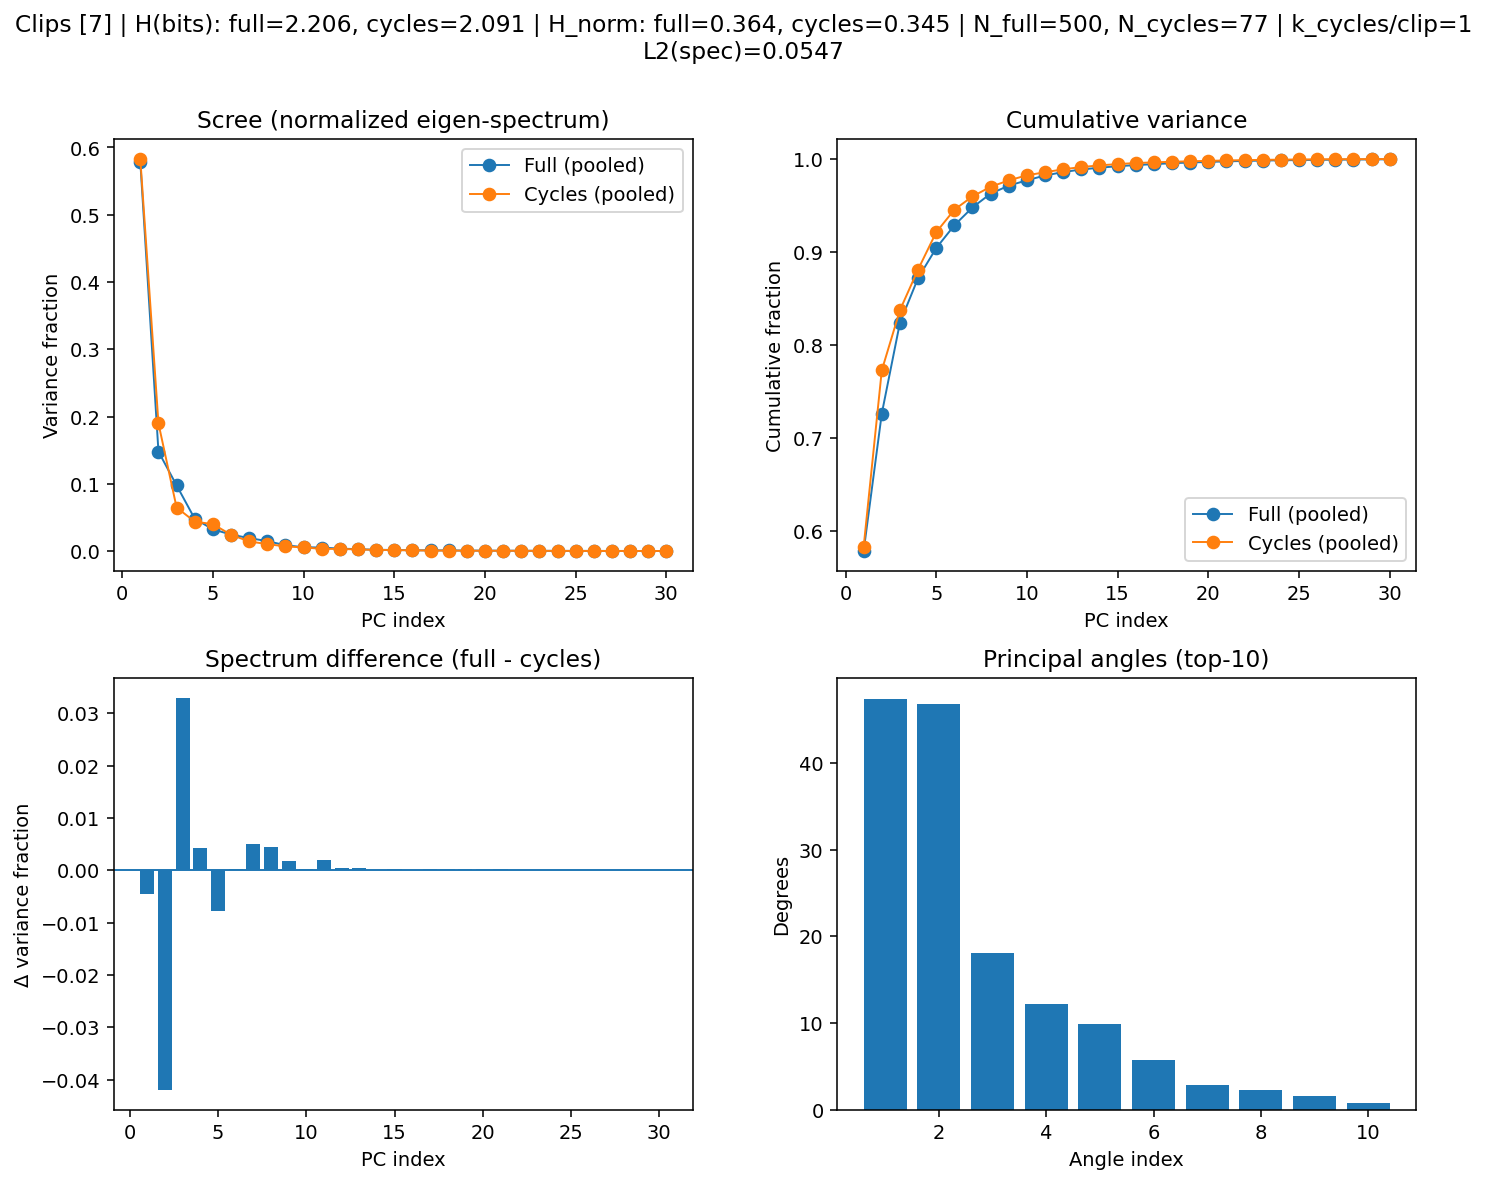

In [25]:
plot_eigenbase_compression_loss(7, all_cycle_dm, rodent_rollout_dir, k_cycles=1)

**Spectrum Differences**:
- Compares how much variance each principal component captures in the full dataset and the cycles dataset.
    - Positive bar means full data has more variance on that PC.
    - Negative bar means cycles have more variance on that PC.

**Principal Angles**:
- Top eigenvector subspaces has very small angles, <2 degrees by PC10.
- The movement subspaces are nearly the same.

### Projection to Full Dataset
If I take the principal directions learned from one dataset (e.g., cycles), how well do they capture the variability of the other dataset (ground truth full behavior)? We take the subspace of the top $k$ principal component, or the top $k$ direction vector in feature space along which the data has maximum variance (eigenvector of the covariance matrix).

- We want to see if the **cycles are high variance subspace** of the full dataset. How much full-dataset variance lies in the directions defined by the $k$ cycle PCs?

#### Cycle Projecting to Full Dataset

Project the full data into the cycle-PC subspace then reconstruct in original coordinates:

$$
Z_{f \leftarrow c}^{(k)} = Q_f \, U_c^{(k)}
$$

$$
\hat{Q}_{f \leftarrow c}^{(k)} = Z_{f \leftarrow c}^{(k)} (U_c^{(k)})^T
$$

#### Fraction of Full Variance Explained:
We want to know how much full-dataset variance lies in the directions defined by the $k$ cycle PCs, so we take sum of variances along those $k$ cycle directions $\mathrm{trace}\left( (U_c^{(k)})^T C_f U_c^{(k)} \right)$ and compare with the total variance in full dataset $\mathrm{trace}(C_f)$.

$$
EV_{f \leftarrow c}(k) =
\frac{\mathrm{trace}\left( (U_c^{(k)})^T C_f U_c^{(k)} \right)}
{\mathrm{trace}(C_f)}
$$

where $C_f = \mathrm{Cov}(Q_f^T)$. The reconstruction error is then just the negated version of the variance explained:

$$
\mathrm{Err}_{f \leftarrow c}(k) = 1 - EV_{f \leftarrow c}(k)
$$

#### Full Dataset Projecting to Cycle

$$
EV_{c \leftarrow f}(k) =
\frac{\mathrm{trace}\left( (U_f^{(k)})^T C_c U_f^{(k)} \right)}
{\mathrm{trace}(C_c)}
$$

$$
\mathrm{Err}_{c \leftarrow f}(k) = 1 - EV_{c \leftarrow f}(k)
$$

/root/vast/kaiwen/TopoVNL/vnl_tda/pipelines/tda/skeletonization/plotting.py:808: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


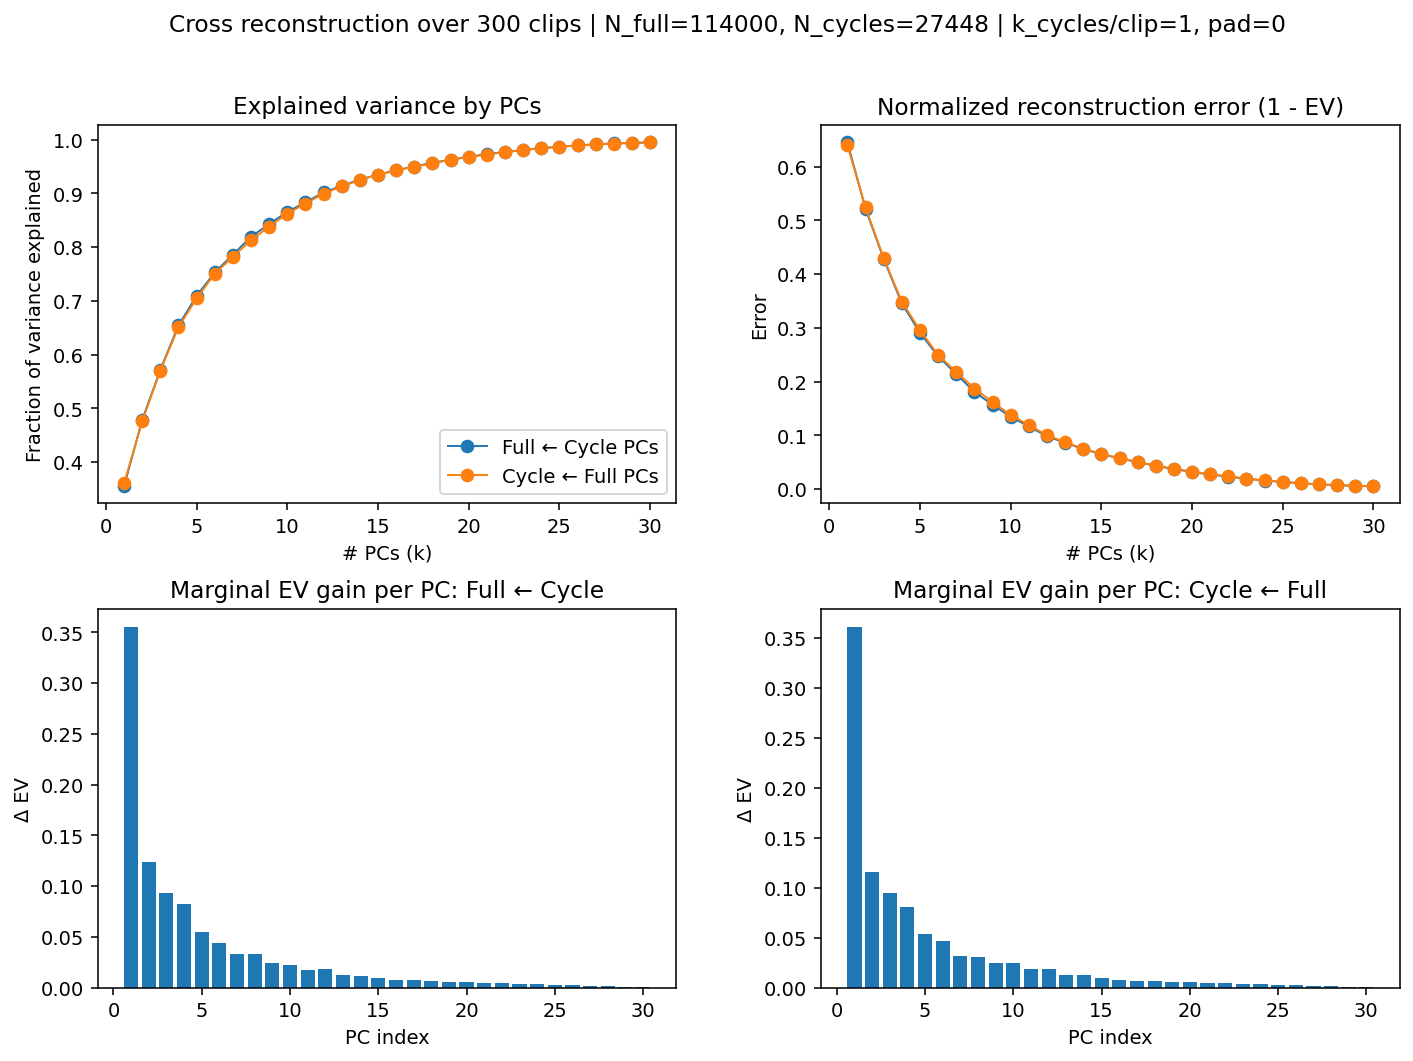

In [24]:
plot_eigenbase_cross_reconstruction(list(range(300)), all_cycle_dm, rodent_rollout_dir, k_cycles=1, pad=0, Kmax=30)

- The dominant directions of variance in cycle data and full-data are extremely similar.
- Cycles span the same latent behavioral structure as the full sequences.
- The full kinematic subspace can almost be recovered using only cycles.

### Compression Per Cluster

This will compare the compression loss in information for **CLUSTERS** by comparing the eigenbase property information of the pool of numerous original 500 qpos frames that have been identified to conatin all of the discrete motifs in the compressed cluster (i.e. if the cluster has tag `rear_walk`, then we will be getting clip only with `rear` and `walk` tags from our manually labeled dataset). Since Eigenbase property doesn't consider orders or dynamics, this approach can work.

In [12]:
csv_path = "../behavior_book.csv" 
cluster_labels = {
    0: "walk",
    1: "groom_walk",
    2: "walk_turn",
    3: "groom_turn",
    4: "rear_turn_walk",
    5: "groom",
    6: "rear_walk",
    7: "rear",
    8: "walk_turn_stay",
    9: "walk_turn_stay",
}

In [48]:
rsults = plot_cluster_eigenbase_cross_reconstruction(
    cluster_dict,
    cluster_labels,
    ['rear_walk', 'groom_turn', 'walk_turn'],
    csv_path,
    rodent_rollout_dir,
    k_cycles_per_clip=1,
    pad=0,
    Kmax=30,
    state_key="qpos",
    plot_error=True,
    n_cycles_sample=5,
    sample_strategy="random",)

Now plot the y-axis as differences in variance explained and x-axis as the number of cycles used along with vertical lines pointing out when the total frames in these cycles surpass $p$ percent of teh total number of frames that the clips with these behaviors have.

- Notice that the clips that have these behaviors presented does not neccessarily mean that they are teh ones we got from the clusters in teh cycles.

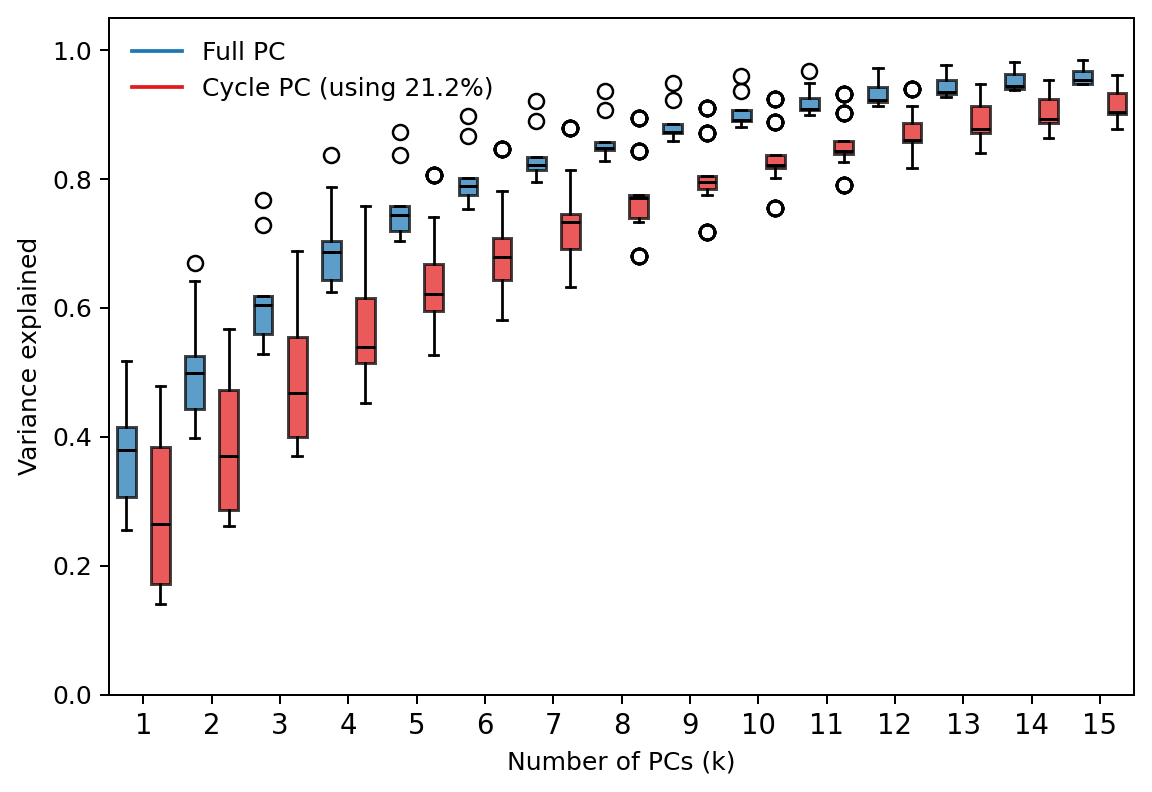

In [37]:
plot_cluster_eigenbase_reconstruction_box(
    cluster_cycles_by_id=cluster_dict,
    cluster_labels=cluster_labels,
    target_clusters=[
    "walk_turn",
    "groom_turn", 
    "groom_walk",
    "rear_turn_walk", 
    "groom", 
    "rear",
    "walk",
    "walk_turn_stay",
    "rear_walk", 
    ],
    csv_path=csv_path,
    rodent_rollout_dir=rodent_rollout_dir,
    k_pc=15,
    n_cycles=35,
    repeats=10,
    sample_strategy="shortest",
    pad=0,
    state_key="qpos",
    seed=0,
)

### What is a fair baseline to compare to?
`Note`: If we just randomly sample frames and compare, when we sample a large quantity, the angles will be very lower than the angles we have for each cycle. This is because uniform sampling is just creating a space of the original space, which is naturally a representative set from the eigenbasis perspective (when the number of frames is large enough). This is one issue with this validation strategy, we can only show that the cycle subspace resembles the original space, but this does  not include the advantage that these cycles have a inherent flow in them.

We don't want to directly see if the cycle and clip identification match up, that's too binary and behaviors are complex.

We can contrast to show our result:
- Compare union of full clips for `groom` to clusters labeled `groom_turn`, `groom_walk`, `groom` for baelines.
- Then compare to `rear` and `walk_turn_stay` for similar type of behaviors; all have stationary component.
- At last compare to `walk`, `rear_turn_walk`, `rear_walk` or other that have no connections with `groom`.

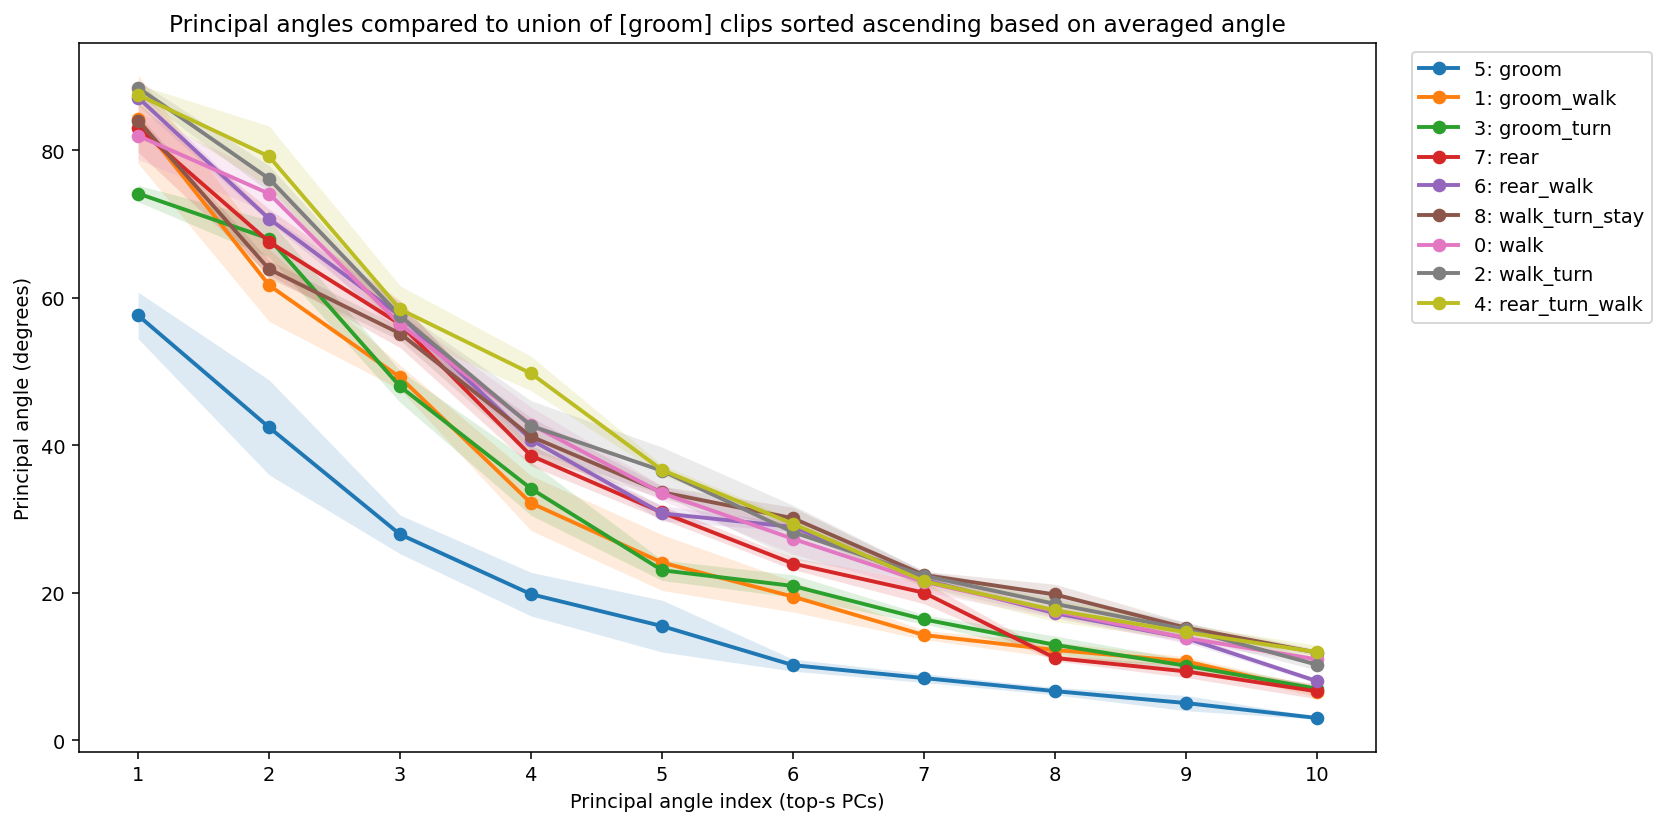

In [12]:
plot_cluster_principal_angles_to_target_union(
    cluster_dict,
    cluster_labels,
    target_clusters=[
    "walk_turn",
    "groom_turn", 
    "groom_walk",
    "rear_turn_walk", 
    "groom", 
    "rear",
    "walk",
    "walk_turn_stay",
    "rear_walk", 
    ],
    csv_path=csv_path,
    rodent_rollout_dir=rodent_rollout_dir,
    target_union="groom",
    k_cycles=50,
    s_top=10,
    repeats=5,
    sample_strategy="random",
    seed=20,
    plot=True
)

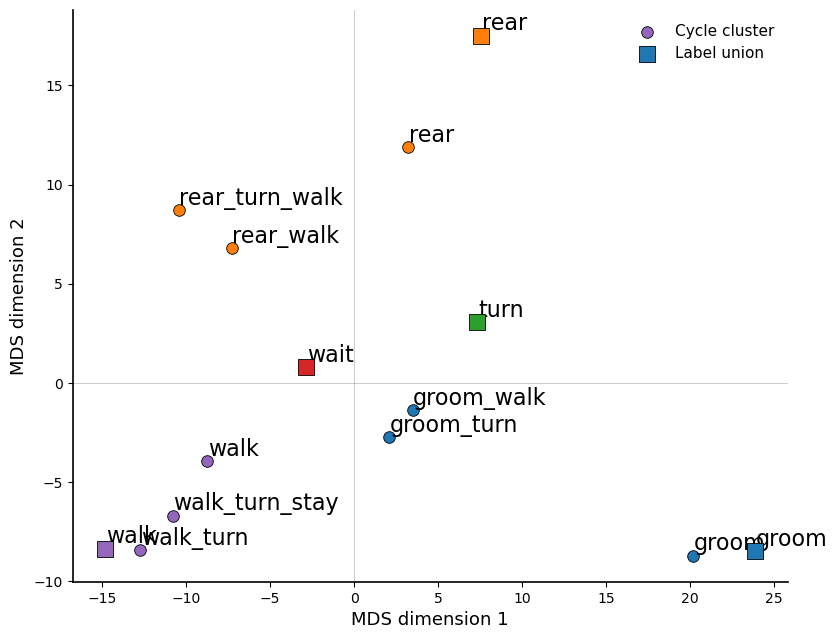

In [21]:
plot_cluster_subspace_mds(
    cluster_cycles_by_id=cluster_dict,
    cluster_labels=cluster_labels,
    target_clusters=[
        "walk_turn",
        "groom_turn", 
        "groom_walk",
        "rear_turn_walk", 
        "groom", 
        "rear",
        "walk",
        "walk_turn_stay",
        "rear_walk", 
    ],
    rodent_rollout_dir=rodent_rollout_dir,
    csv_path=csv_path,
    label_unions=("walk","rear","groom","turn","wait"),
    k_cycles=50,
    s_top=10,
    pad=0,
    state_key="qpos",
    sample_strategy="shortest",
    seed=0,
    plot=True,
    figsize=(8.5, 6.5),
    save_path="cluster_subspace_mds.pdf",
)

---

# Step 7: Clusters in Joint Space

We can examine different properties of different clusters in the joint space, particularly, we can look at the changes in (x,y,z) for each cluster across all different cycles and see if there exist meaningful relationships.

The result is sorted based on x + y descending:
- Any cluster pivoting `turn` component in it (i.e. `walk_turn_stay`, `rear_walk`, `rear_turn_walk`) wil have the highest changes in (x,y) since more horizontal displacement will occur.
    - It's likely that we observe `rear_walk` similar to `rear_turn_walk` because `rear_walk` usually contain a pivot from walk to rear.
- Any cluster with `rear` will have greater changes in the z component.
- Any cluster with `grooming` will have the least (x,y) component.
    - `groom_turn` should have more movement on (x,y) component compared to `rear`, particularly compared to pure `groom`.

Similarly, we can overlay the previous result with the union of clips and we will observe similar trend.

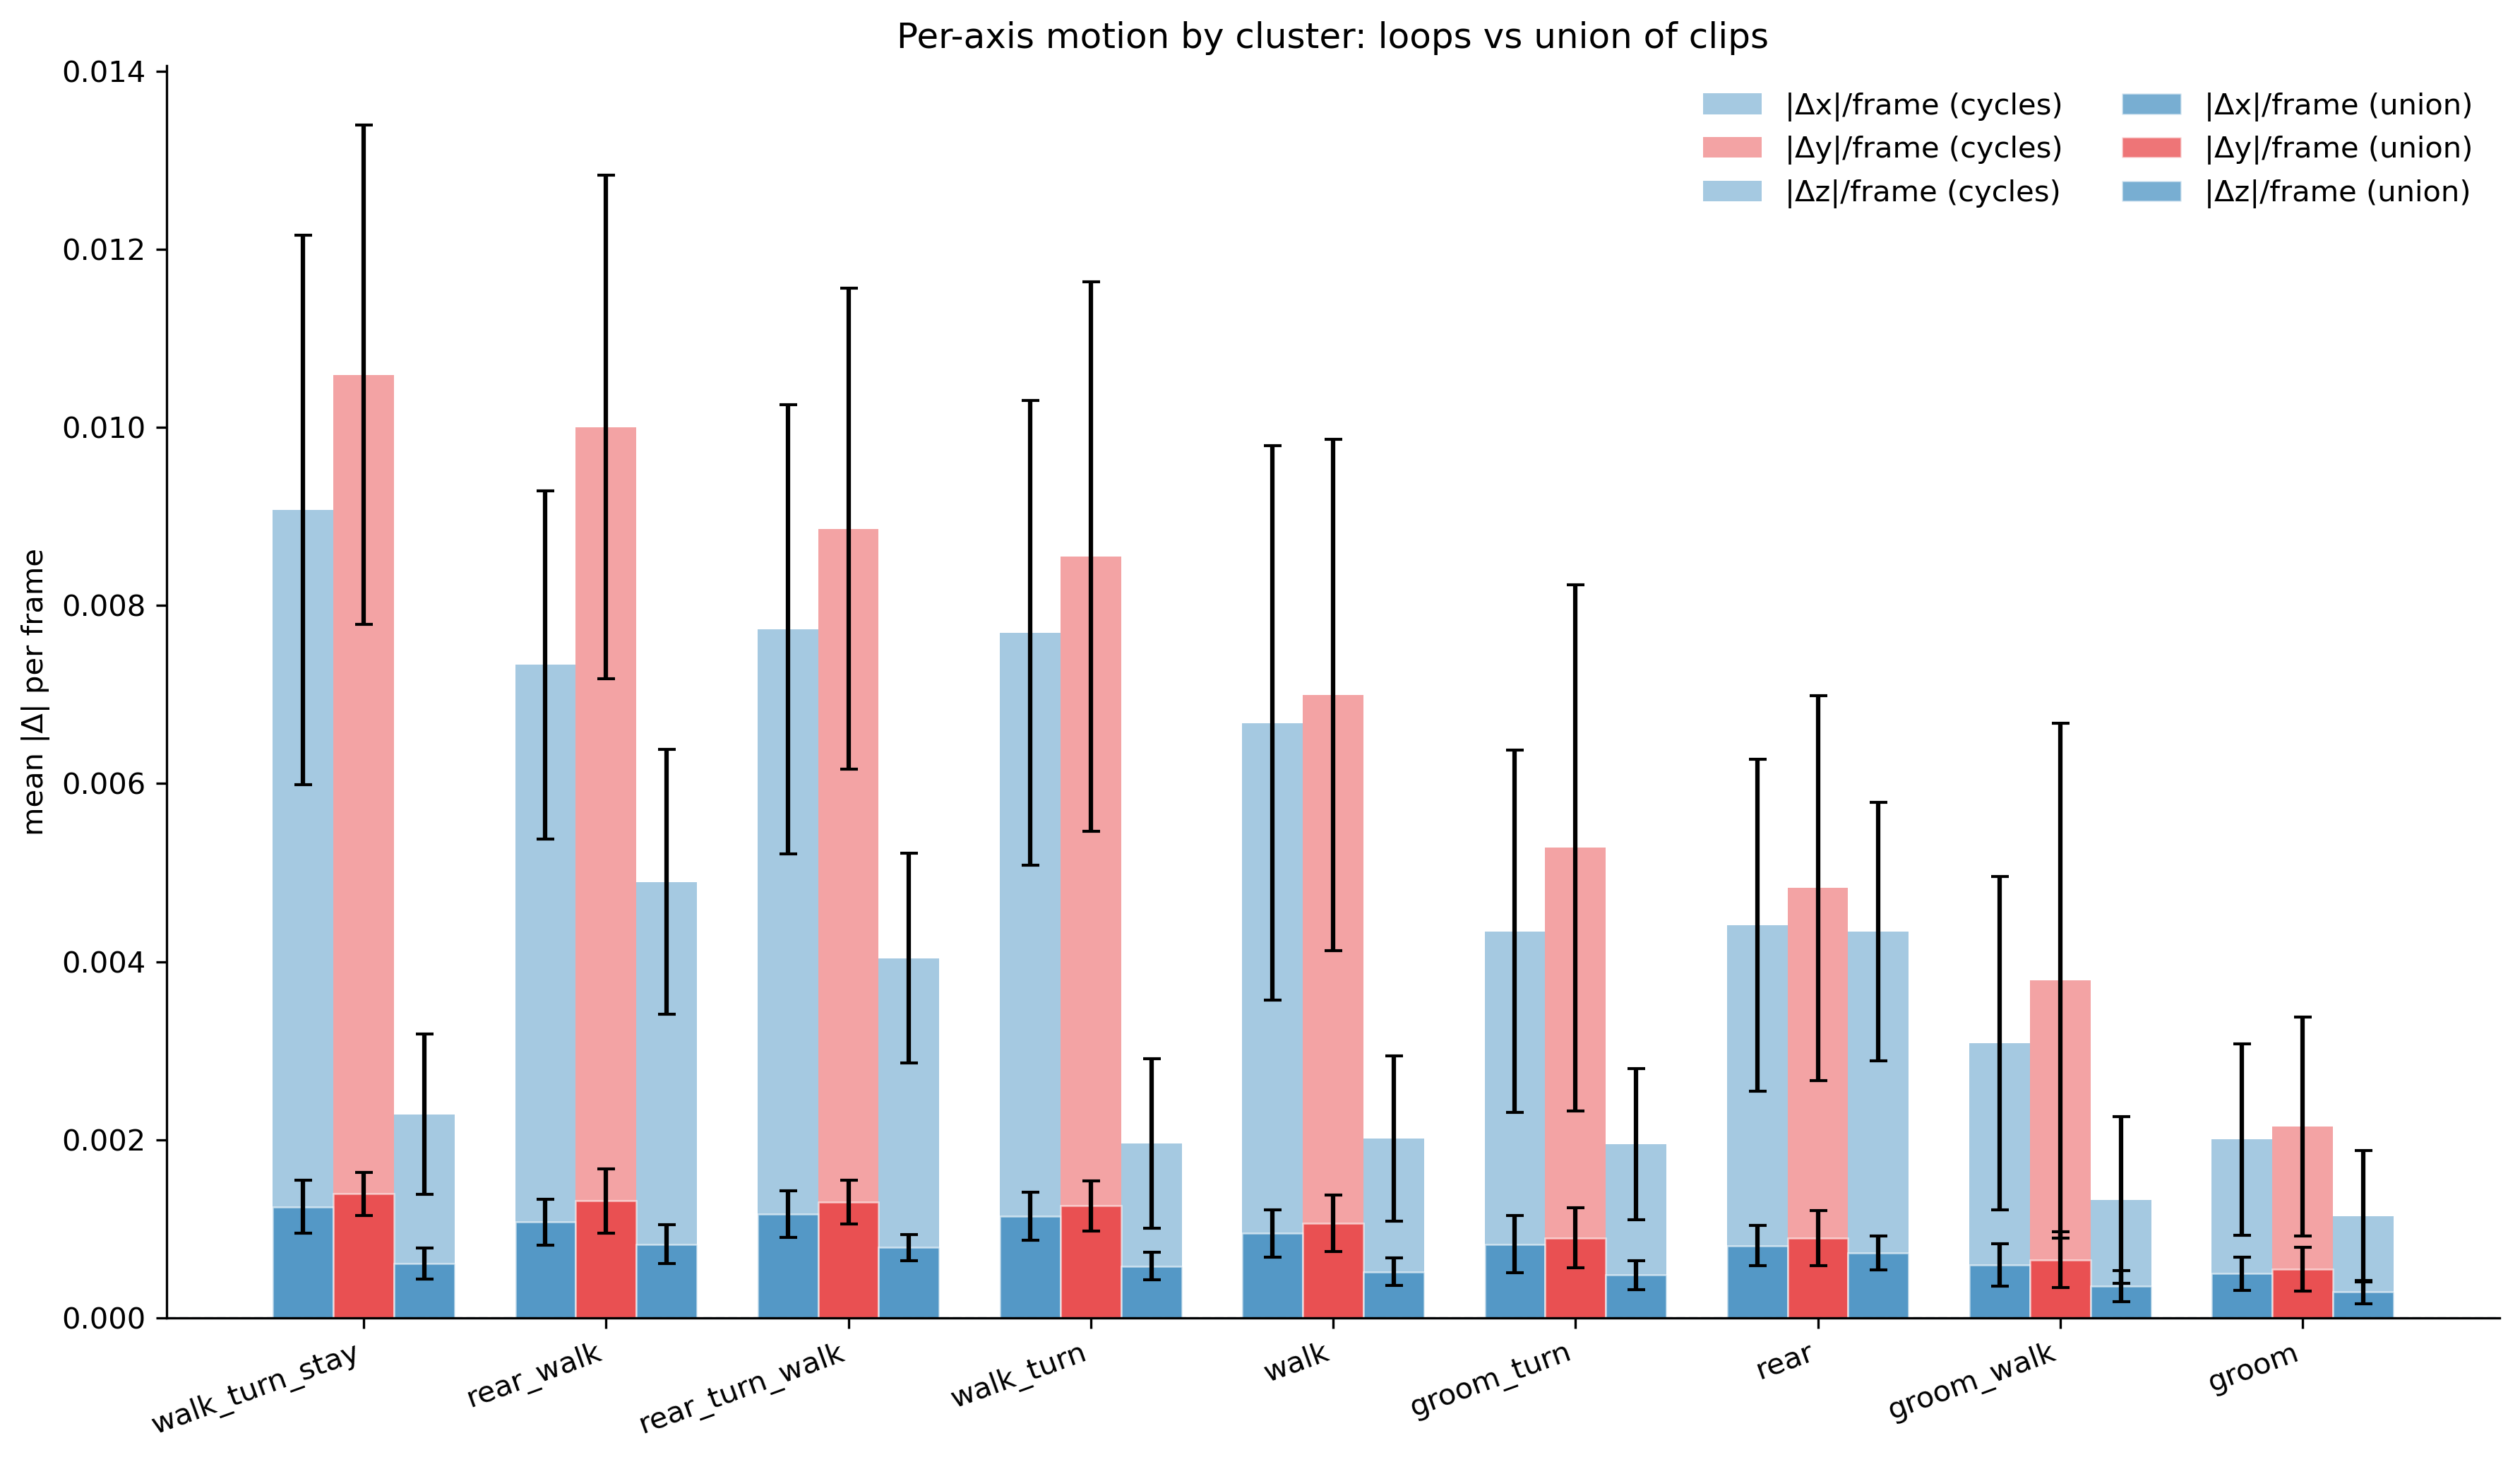

In [45]:
compare_clusters_axis_motion_with_union(
    cluster_dict,
    cluster_labels,
    target_cluster_names=[
        "walk_turn",
        "groom_turn", 
        "groom_walk",
        "rear_turn_walk", 
        "groom", 
        "rear",
        "walk",
        "walk_turn_stay",
        "rear_walk", 
        ],
    max_loops=200,
    out_pdf="cluster_axis_compare_union.pdf",
    rodent_rollout_dir=rodent_rollout_dir,
    figsize=(12,7),
)

---

# Step 8: Benchmark Comparison
We will be performing benchmaring experiments to see the performance of other existing methods:

1. W2 + kMeans on full clip (ablating TDA compression).
2. kMeans on intention space.

All the functionalities used below are exact copies of what we have in the above sections for the compressed cycle:

### W2 + kMeans on full clip
To keep everything the same, the easiest comparison that we can make is to compare the segmentation / clustering via doing W2 + OPT + Kmeans but with the whole clips' intention, not just the cycle index.

In [22]:
def make_fake_all_clip_loops(intention, n_clips=None):
    if n_clips is None:
        n_clips = intention.shape[0]
    all_cycle_dm = []
    for cid in range(n_clips):
        T = intention[cid].shape[0]
        all_cycle_dm.append([np.arange(T, dtype=int)])
    return all_cycle_dm

all_cycle_dm_fake = make_fake_all_clip_loops(int_rodent, n_clips=500)

cluster_dict_full_int, all_cleaned_loops_fake = cluster_vpath_with_wasserstein2d_fixedlen_kmeans(
    all_cycle_dm_fake,
    int_rodent,
    pad=0,
    min_len=1,
    max_len=500,
    n_clusters=10,
    n_clips=500,
    drop_nearby_loop_num=0,
    skip_clips=[37, 152, 163, 274, 281],
    squared_cost=False,
    only_max=False,
    use_full_union=False,
)
    
plot_vpath_cluster(cluster_dict_full_int, embeds3d, clip_frame_to_global)

In [60]:
cluster_chunks_full_int = chunk_loops_by_clustered_vpath(cluster_dict_full_int, rodent_rollout_dir, pad=0, sample=5)

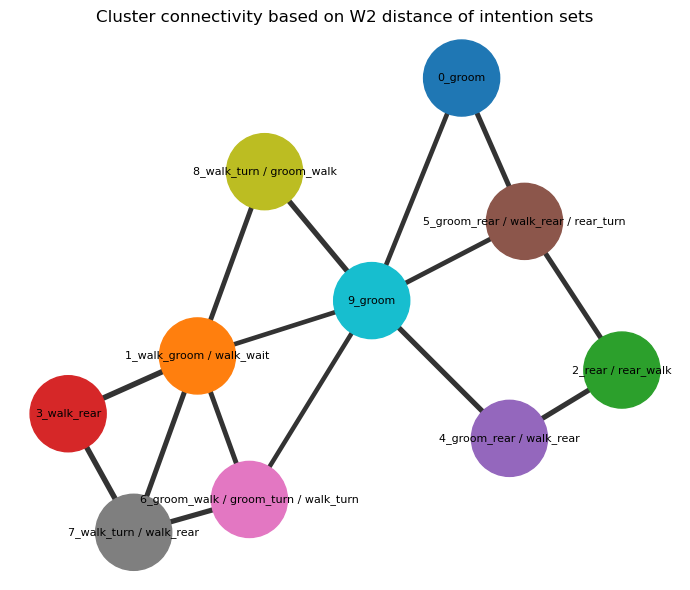

In [55]:
cluster_labels = {
    0: "groom",
    1: "walk_groom / walk_wait",
    2: "rear / rear_walk",
    3: "walk_rear",
    4: "groom_rear / walk_rear",
    5: "groom_rear / walk_rear / rear_turn",
    6: "groom_walk / groom_turn / walk_turn",
    7: "walk_turn / walk_rear",
    8: "walk_turn / groom_walk",
    9: "groom",
}

prototypes = build_cluster_prototypes_from_dict(cluster_dict_full_int, int_rodent, target_len=50, agg="mean")
C, ids = cluster_distance_matrix(prototypes, metric="emd")
G = cluster_knn_graph(C, ids, cluster_labels, k=2, threshold=None)
draw_cluster_intention_graph(G, cluster_labels)

### kMeans on intention space

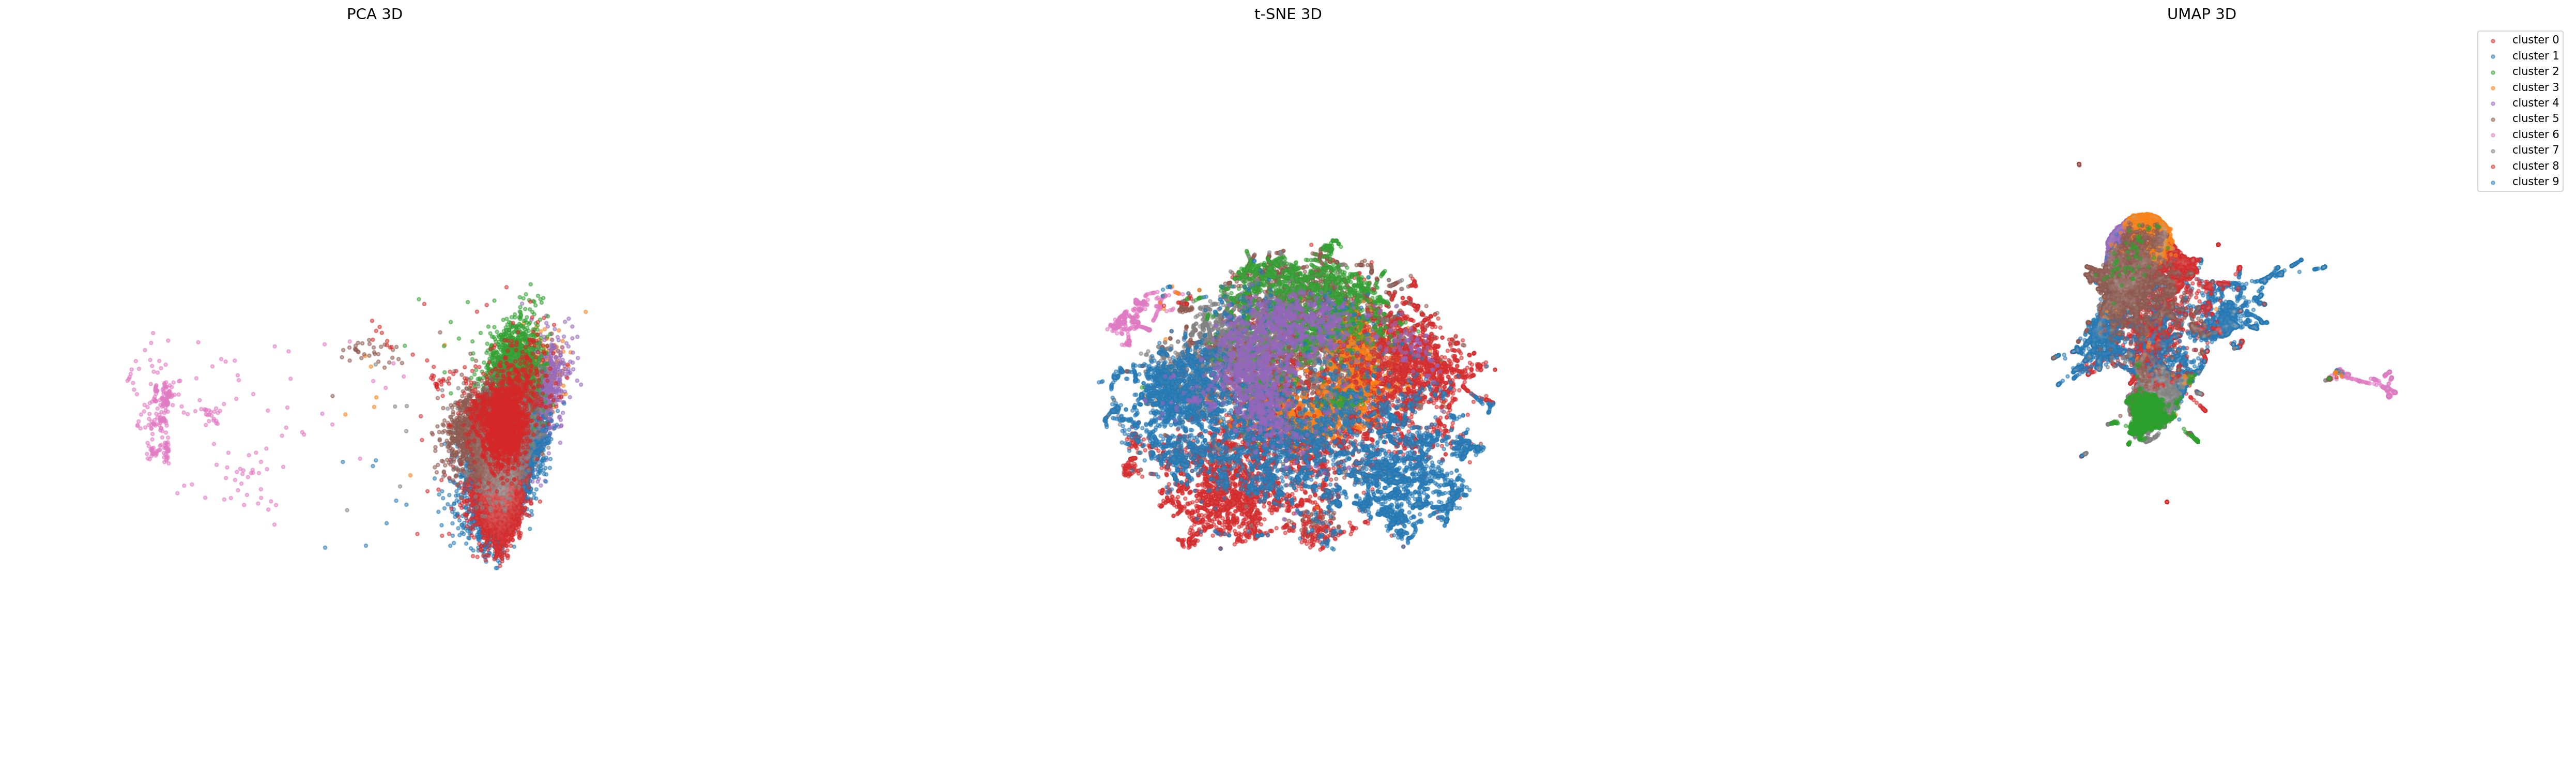

Saved combined plot to vpath_cluster_all.png


In [17]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

def cluster_intention_simple(intention, n_clusters=10, use_pca=True, pca_dim=10, n_clips=None):
    """
    Clusters intention trajectories directly (no OT, no per-loop distance).
    Returns cluster_dict in same format as Wasserstein version.
    """
    if n_clips is None:
        n_clips = intention.shape[0]
    X = intention[:n_clips].reshape(-1, intention.shape[-1])  # (n_clips*T, dim)
    if use_pca:
        pca = PCA(n_components=pca_dim)
        Xp = pca.fit_transform(X)
    else:
        Xp = X
    labels = KMeans(n_clusters=n_clusters, random_state=0, n_init="auto").fit_predict(Xp)
    T = intention.shape[1]
    clip_ids = np.repeat(np.arange(n_clips), T)
    frame_ids = np.tile(np.arange(T), n_clips)
    cluster_dict = {cid: [] for cid in range(n_clusters)}
    for lbl, clip_id, frame_id in zip(labels, clip_ids, frame_ids):
        cluster_dict[lbl].append((clip_id, np.array([frame_id])))
    return cluster_dict

cluster_dict_raw_kmeans = cluster_intention_simple(
    int_rodent,
    n_clusters=10,
    use_pca=False,
    pca_dim=10,
    n_clips=500
)

plot_vpath_cluster(cluster_dict_raw_kmeans, embeds3d, clip_frame_to_global)

In [18]:
from collections import defaultdict

def merge_cluster_frames(cluster_dict_raw):
    merged = {}
    for cid, entries in cluster_dict_raw.items():
        by_clip = defaultdict(list)
        for clip_id, frames in entries:
            by_clip[clip_id].extend(frames.tolist())
        merged[cid] = [(clip_id, np.sort(np.unique(by_clip[clip_id]))) for clip_id in by_clip]
    return merged

cluster_dict_raw_kmeans = merge_cluster_frames(cluster_dict_raw_kmeans)

In [51]:
cluster_labels = {
    0: "walk",
    1: "walk_turn",
    2: "rear",
    3: "one_step",
    4: "walk",
    5: "stay",
    6: "stay",
    7: "rear",
    8: "rear / groom_walk",
    9: "groom",
}

prototypes = build_cluster_prototypes_from_dict(cluster_dict_raw_kmeans, int_rodent, target_len=50, agg="mean")
C, ids = cluster_distance_matrix(prototypes, metric="emd")
G = cluster_knn_graph(C, ids, cluster_labels, k=2, threshold=None)
draw_cluster_intention_graph(G, cluster_labels)

Making the two graphs appear together to help visualize better:

In [ ]:
def draw_cluster_intention_graph(
    G,
    cluster_labels,
    ax=None,
    font_size=14,
    weight_exponent=1.6,
    min_width=0.8,
    max_width=6.0,
    cmap=plt.cm.tab20,
    name_to_color_idx=None,
    colors_arr=None,
):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    pos = nx.spring_layout(G, seed=5)

    # color by cluster NAME (consistent across graphs)
    node_colors = [
        colors_arr[name_to_color_idx[cluster_labels[n]]]
        for n in G.nodes()
    ]

    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        node_size=3600,
        node_color=node_colors,
    )

    edges = list(G.edges(data=True))
    if edges:
        weights = np.array([d.get("weight", 1.0) for _, _, d in edges])
        w_min, w_max = weights.min(), weights.max()
        w_norm = (weights - w_min) / (w_max - w_min + 1e-8)
        w_scaled = min_width + (max_width - min_width) * (w_norm ** weight_exponent)
        nx.draw_networkx_edges(
            G, pos, edgelist=[(u, v) for u, v, _ in edges],
            ax=ax, width=w_scaled, alpha=0.9
        )

    labels = {cid: cluster_labels[cid] for cid in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=font_size, ax=ax)

    ax.set_axis_off()

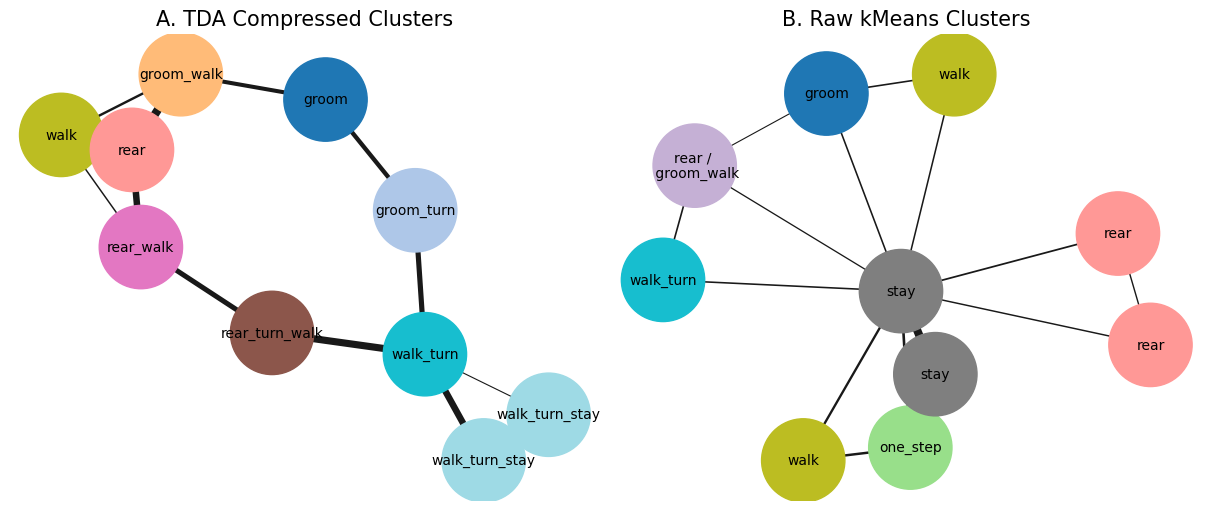

In [56]:
cluster_labels1 = {
    0: "walk",
    1: "groom_walk",
    2: "walk_turn",
    3: "groom_turn",
    4: "rear_turn_walk",
    5: "groom",
    6: "rear_walk",
    7: "rear",
    8: "walk_turn_stay",
    9: "walk_turn_stay",
}


cluster_labels2 = {
    0: "walk",
    1: "walk_turn",
    2: "rear",
    3: "one_step",
    4: "walk",
    5: "stay",
    6: "stay",
    7: "rear",
    8: "rear / groom_walk",
    9: "groom",
}  

prototypes1 = build_cluster_prototypes_from_dict(cluster_dict, int_rodent, target_len=50, agg="mean")
C1, ids1 = cluster_distance_matrix(prototypes1, metric="emd")
G1 = cluster_knn_graph(C1, ids1, cluster_labels1, k=2, threshold=None)

prototypes2 = build_cluster_prototypes_from_dict(cluster_dict_raw_kmeans, int_rodent, target_len=50, agg="mean")
C2, ids2 = cluster_distance_matrix(prototypes, metric="emd")
G2 = cluster_knn_graph(C2, ids2, cluster_labels2, k=2, threshold=None)

all_names = list(set(cluster_labels1.values()) | set(cluster_labels2.values()))
all_names = sorted(all_names)

cmap = plt.cm.tab20
name_to_color_idx = {name: i for i, name in enumerate(all_names)}
colors_arr = cmap(np.linspace(0, 1, len(all_names)))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

draw_cluster_intention_graph(
    G1,
    cluster_labels1,
    ax=axes[0],
    font_size=10,
    weight_exponent=1.0,
    name_to_color_idx=name_to_color_idx,
    colors_arr=colors_arr,
)
axes[0].set_title("A. TDA Compressed Clusters", fontsize=15)

draw_cluster_intention_graph(
    G2,
    cluster_labels2,
    ax=axes[1],
    font_size=10,
    weight_exponent=1.0,
    name_to_color_idx=name_to_color_idx,
    colors_arr=colors_arr,
)
axes[1].set_title("B. Raw kMeans Clusters", fontsize=15)

fig.savefig("cluster_graph_pair.pdf", dpi=350, bbox_inches="tight", transparent=True)
plt.show()

---
---